# Limpieza y preprocesamiento de datos

## Ingesta

In [2]:
# Recuperación de contenido del archivo CSV y creación de un DataFrame de pandas
import pandas as pd

# Cargar el archivo CSV en un DataFrame
df = pd.read_csv('retail_x_clientes.csv')
df

,customer_id,edad,ingresos,ciudad,fecha_ultima_compra,num_compras,deuda,churn
0,1860,50,23962.22,Ciudad de México,2023-08-30,4,5365.92,1.0
1,4772,49,NaN,puebla,2023-06-05,5,4692.15,1.0
2,4092,17,NaN,CDMX,2022-11-29,9,4617.36,1.0
3,1466,40,NaN,Puebla,2021-10-09,5,2101.78,0.0
4,5426,21,9998.37,Ciudad de México,2023-09-02,3,-1798.42,0.0
...,...,...,...,...,...,...,...,...
9995,5931,43,14059.39,CDMX,2021-07-31,6,2035.49,0.0
9996,2691,31,9851.20,CDMX,2022-01-17,4,4674.32,1.0
9997,5550,15,17832.33,México D.F.,2021-02-10,1,6148.24,1.0
9998,5408,44,13644.92,Puebla,2021-10-30,2,3710.74,1.0


## Identificación de características generales del conjunto de datos

En esta fase, se realiza una inspección general de la estructura del conjunto de datos con el objetivo de identificar características generales con número de items, tipos de datos, datos nulos, items etiquetados/ no etiquetados, entre otras.

In [3]:
# Recuperando una muestra de los datos para inspección
df.head()

,customer_id,edad,ingresos,ciudad,fecha_ultima_compra,num_compras,deuda,churn
0,1860,50,23962.22,Ciudad de México,2023-08-30,4,5365.92,1.0
1,4772,49,NaN,puebla,2023-06-05,5,4692.15,1.0
2,4092,17,NaN,CDMX,2022-11-29,9,4617.36,1.0
3,1466,40,NaN,Puebla,2021-10-09,5,2101.78,0.0
4,5426,21,9998.37,Ciudad de México,2023-09-02,3,-1798.42,0.0


In [4]:
df.tail()

,customer_id,edad,ingresos,ciudad,fecha_ultima_compra,num_compras,deuda,churn
9995,5931,43,14059.39,CDMX,2021-07-31,6,2035.49,0.0
9996,2691,31,9851.20,CDMX,2022-01-17,4,4674.32,1.0
9997,5550,15,17832.33,México D.F.,2021-02-10,1,6148.24,1.0
9998,5408,44,13644.92,Puebla,2021-10-30,2,3710.74,1.0
9999,1227,42,NaN,Puebla,2024-02-24,6,2112.72,1.0


In [5]:
# Visualización de información general del DataFrame
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   customer_id          10000 non-null  int64  
 1   edad                 10000 non-null  int64  
 2   ingresos             7000 non-null   float64
 3   ciudad               10000 non-null  str    
 4   fecha_ultima_compra  10000 non-null  str    
 5   num_compras          10000 non-null  int64  
 6   deuda                10000 non-null  float64
 7   churn                8999 non-null   float64
dtypes: float64(3), int64(3), str(2)
memory usage: 625.1 KB


Derivado de la observación que se ha realizado a través de las muestras proporcionadas por .head() y por .tail(), además de la la tarjeta informativa del dataframe se han realizado los siguientes hallazgos:
- En el caso de *ciudad* algunas denominaciones hacen referencia a la misma ubicación, específicamente: CDMX, Ciudad de México, México D.F.
- En el caso de *fecha_ultima_compra* se ha identificado que el tipo de dato es cadena y no *date*, esto afecta el filtrado del contenido a través de marcas de tiempo.
- Con respecto a *ingresos* y *churn* se puede observar que hay un faltante de datos de 3000 y 1001 datos respectivamente.

## Tratamiento de los datos duplicados

In [48]:
# Identificación de los valores duplicados en el DataFrame
df[df.duplicated(subset=['customer_id'])].count()

customer_id            5719
edad                   5719
ingresos               3963
ciudad                 5719
fecha_ultima_compra    5719
num_compras            5719
deuda                  5719
churn                  5132
dtype: int64

In [49]:
# Identificando registros duplicados de customer_id y mostrando los registros duplicados
df.duplicated(subset=['customer_id']).sum()

np.int64(5719)

In [50]:
# Listado de los registros duplicados de customer_id
df[df.duplicated(subset=['customer_id'], keep=False)].sort_values(by='customer_id')

,customer_id,edad,ingresos,ciudad,fecha_ultima_compra,num_compras,deuda,churn
1686,1001,15,NaN,México D.F.,2023-02-12,5,6127.48,1.0
5933,1001,50,13251.88,puebla,2023-02-11,4,4224.34,0.0
1572,1001,32,14210.64,Puebla,2023-03-04,7,7655.77,1.0
8525,1002,38,NaN,México D.F.,2023-10-26,4,5875.85,1.0
4064,1002,51,NaN,Ciudad de México,2022-07-09,5,3550.15,1.0
...,...,...,...,...,...,...,...,...
9515,5995,48,13483.33,Puebla,2023-10-17,4,5553.79,0.0
6337,5995,52,10196.82,Ciudad de México,2021-08-16,6,4217.40,1.0
9667,5995,34,NaN,CDMX,2023-09-23,5,4192.25,1.0
8991,5997,26,16262.02,Ciudad de México,2022-02-04,5,5098.87,0.0


### --- Eliminación de los datos duplicados ---

In [51]:
# Identificación del formato de fechas
s = df["fecha_ultima_compra"].dropna().astype("string").str.strip()

patrones = s.str.replace(r"\d", "9", regex=True).value_counts()
print(patrones)

fecha_ultima_compra
9999-99-99    10000
Name: count, dtype: Int64


In [52]:
# Conversión de str a date
df["fecha_ultima_compra"] = pd.to_datetime(
    df["fecha_ultima_compra"],
    errors="coerce"
)

In [53]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   customer_id          10000 non-null  int64         
 1   edad                 10000 non-null  int64         
 2   ingresos             7000 non-null   float64       
 3   ciudad               10000 non-null  str           
 4   fecha_ultima_compra  10000 non-null  datetime64[us]
 5   num_compras          10000 non-null  int64         
 6   deuda                10000 non-null  float64       
 7   churn                8999 non-null   float64       
dtypes: datetime64[us](1), float64(3), int64(3), str(1)
memory usage: 625.1 KB


### --- Datos sin repetidos ---

In [54]:
# Elimina los registros exactamente duplicados
df_sin_duplicados = df.drop_duplicates()
df_sin_duplicados

,customer_id,edad,ingresos,ciudad,fecha_ultima_compra,num_compras,deuda,churn
0,1860,50,23962.22,Ciudad de México,2023-08-30,4,5365.92,1.0
1,4772,49,NaN,puebla,2023-06-05,5,4692.15,1.0
2,4092,17,NaN,CDMX,2022-11-29,9,4617.36,1.0
3,1466,40,NaN,Puebla,2021-10-09,5,2101.78,0.0
4,5426,21,9998.37,Ciudad de México,2023-09-02,3,-1798.42,0.0
...,...,...,...,...,...,...,...,...
9995,5931,43,14059.39,CDMX,2021-07-31,6,2035.49,0.0
9996,2691,31,9851.20,CDMX,2022-01-17,4,4674.32,1.0
9997,5550,15,17832.33,México D.F.,2021-02-10,1,6148.24,1.0
9998,5408,44,13644.92,Puebla,2021-10-30,2,3710.74,1.0


In [55]:
# Elimina los registros duplicaodos por customer_id manteniendo el mas reciente
df_sin_duplicados = (
    df.sort_values("fecha_ultima_compra", ascending=False)
      .drop_duplicates(subset="customer_id", keep="first")
      .reset_index(drop=True)
)

In [56]:
df_sin_duplicados

,customer_id,edad,ingresos,ciudad,fecha_ultima_compra,num_compras,deuda,churn
0,2741,36,NaN,Guadalajara,2024-04-14,3,3169.52,0.0
1,3990,65,NaN,Puebla,2024-04-14,4,5453.18,1.0
2,5005,31,NaN,puebla,2024-04-14,4,2990.19,1.0
3,3040,41,10429.64,México D.F.,2024-04-14,3,2331.66,1.0
4,4357,26,5354.56,puebla,2024-04-14,5,3379.76,1.0
...,...,...,...,...,...,...,...,...
4276,2833,40,10549.66,CDMX,2021-01-07,12,4376.32,1.0
4277,1436,49,22627.81,Ciudad de México,2021-01-05,4,4935.57,0.0
4278,5205,30,12388.96,Puebla,2021-01-05,5,8460.79,0.0
4279,4864,59,19272.03,CDMX,2021-01-02,5,6774.73,1.0


In [57]:
df_sin_duplicados["ciudad"].unique()

<StringArray>
['Guadalajara', 'Puebla', 'puebla', 'México D.F.', 'CDMX', 'Ciudad de México']
Length: 6, dtype: str

In [58]:
df_sin_duplicados["ciudad"].value_counts(dropna=False)

ciudad
CDMX                851
Ciudad de México    851
Puebla              822
puebla              670
México D.F.         634
Guadalajara         453
Name: count, dtype: int64

In [59]:
# Normalizando denominaciones de las ciudades
ciudad_limpia = (
    df_sin_duplicados["ciudad"]
      .astype("string")
      .str.strip()
      .str.replace(r"\s+", " ", regex=True)
      .str.casefold()
)

mapeo = {
    "cdmx": "CDMX",
    "méxico d.f.": "CDMX",
    "ciudad de méxico": "CDMX",
    "puebla": "Puebla",
    "guadalajara": "Guadalajara"
}

df_sin_duplicados["ciudad"] = ciudad_limpia.replace(mapeo)
df_sin_duplicados

,customer_id,edad,ingresos,ciudad,fecha_ultima_compra,num_compras,deuda,churn
0,2741,36,NaN,Guadalajara,2024-04-14,3,3169.52,0.0
1,3990,65,NaN,Puebla,2024-04-14,4,5453.18,1.0
2,5005,31,NaN,Puebla,2024-04-14,4,2990.19,1.0
3,3040,41,10429.64,CDMX,2024-04-14,3,2331.66,1.0
4,4357,26,5354.56,Puebla,2024-04-14,5,3379.76,1.0
...,...,...,...,...,...,...,...,...
4276,2833,40,10549.66,CDMX,2021-01-07,12,4376.32,1.0
4277,1436,49,22627.81,CDMX,2021-01-05,4,4935.57,0.0
4278,5205,30,12388.96,Puebla,2021-01-05,5,8460.79,0.0
4279,4864,59,19272.03,CDMX,2021-01-02,5,6774.73,1.0


### ----------------------------------------------------------------

## Tratamiento de los datos faltantes

Los datos faltantes ocurren o se identifican cuando por alguna razón, éstos no se registran en una o mas ocasiones. Algunos mecanismos de pérdida  de los datos pueden ser:
- MCAR (*Missing Completely ar Random*): Cuando la causa de la ausencia no esta relacionada con ninguna otra variable.
- MAR (*Missing at Random*): Cuando la ausencia del dato depende de otras variables (datos derivados).
- MNAR (*Missing not at Random*): Cuando la ausencia del datos depende directamente de otro valor faltante.

### Criterios para la selección de un método de imputación

Al proceso de sustitución de los datos nulos dentro de un conjunto de datos se le denomina *imputación* y los criterios que se pueden seguir para realizar esto son:
- Basado en el porcentaje de datos nulos
    - Si es menor que 5% entonces se pueden considerar métricas de tendencia central o incluso, la eliminación de los registros.
    - Si se considera la imputación por Media o Mediana:
        - Media en el caso de que la variable se simétrica y gaussiana (no tenga valores atípicos).
        - Mediana que es resistente a los valores atípicos
- Basado en condicionales o modelos
    - Si el porcentaje es mayor al 5% pero menor al 10%
        - Condicionales: Asignar una media de tendencia central basada en grupos
        - Modelos: Este criterio esta basado en algoritmos de aprendizaje automático (ML) tales como KNN (Vecinos mas cercanos).
    - Si el porcentaje es mayor al 10%, se pueden ocupar los metodos anteriores o la eliminación de los mismos.

In [9]:
# Conteo de valores nulos y su porcentaje en cada columna del DataFrame
nulos = pd.DataFrame({
    'Nulos_absolutos': df.isna().sum(),
    'Porcentaje_%': (df.isna().mean() * 100).round(2)
})
print("--- Distribución de los valores nulos ---")
print(nulos)

--- Distribución de los valores nulos ---
                     Nulos_absolutos  Porcentaje_%
customer_id                        0          0.00
edad                               0          0.00
ingresos                        3000         30.00
ciudad                             0          0.00
fecha_ultima_compra                0          0.00
num_compras                        0          0.00
deuda                              0          0.00
churn                           1001         10.01


### --- Nulos del conjunto sin repetidos ---

In [61]:
# Conteo de valores nulos y su porcentaje en cada columna del DataFrame
nulos_sin_repeticion = pd.DataFrame({
    'Nulos_absolutos': df_sin_duplicados.isna().sum(),
    'Porcentaje_%': (df_sin_duplicados.isna().mean() * 100).round(2)
})
print("--- Distribución de los valores nulos ---")
print(nulos_sin_repeticion)

--- Distribución de los valores nulos ---
                     Nulos_absolutos  Porcentaje_%
customer_id                        0          0.00
edad                               0          0.00
ingresos                        1267         29.60
ciudad                             0          0.00
fecha_ultima_compra                0          0.00
num_compras                        0          0.00
deuda                              0          0.00
churn                            421          9.83


In [62]:
# Eliminar datos nulos de la columna churn
df_sin_duplicados = df_sin_duplicados.dropna(subset=["churn"])
df_sin_duplicados

,customer_id,edad,ingresos,ciudad,fecha_ultima_compra,num_compras,deuda,churn
0,2741,36,NaN,Guadalajara,2024-04-14,3,3169.52,0.0
1,3990,65,NaN,Puebla,2024-04-14,4,5453.18,1.0
2,5005,31,NaN,Puebla,2024-04-14,4,2990.19,1.0
3,3040,41,10429.64,CDMX,2024-04-14,3,2331.66,1.0
4,4357,26,5354.56,Puebla,2024-04-14,5,3379.76,1.0
...,...,...,...,...,...,...,...,...
4276,2833,40,10549.66,CDMX,2021-01-07,12,4376.32,1.0
4277,1436,49,22627.81,CDMX,2021-01-05,4,4935.57,0.0
4278,5205,30,12388.96,Puebla,2021-01-05,5,8460.79,0.0
4279,4864,59,19272.03,CDMX,2021-01-02,5,6774.73,1.0


In [63]:
# Conteo de valores nulos y su porcentaje en cada columna del DataFrame
nulos_sin_repeticion = pd.DataFrame({
    'Nulos_absolutos': df_sin_duplicados.isna().sum(),
    'Porcentaje_%': (df_sin_duplicados.isna().mean() * 100).round(2)
})
print("--- Distribución de los valores nulos ---")
print(nulos_sin_repeticion)

--- Distribución de los valores nulos ---
                     Nulos_absolutos  Porcentaje_%
customer_id                        0           0.0
edad                               0           0.0
ingresos                        1158          30.0
ciudad                             0           0.0
fecha_ultima_compra                0           0.0
num_compras                        0           0.0
deuda                              0           0.0
churn                              0           0.0


In [64]:
# Conteo de valores nulos por ciudad
nulos_por_ciudad = df_sin_duplicados.isna().groupby(df_sin_duplicados["ciudad"], dropna=False).sum()
print(nulos_por_ciudad)

             customer_id  edad  ingresos  ciudad  fecha_ultima_compra  \
ciudad                                                                  
CDMX                   0     0       593       0                    0   
Guadalajara            0     0       119       0                    0   
Puebla                 0     0       446       0                    0   

             num_compras  deuda  churn  
ciudad                                  
CDMX                   0      0      0  
Guadalajara            0      0      0  
Puebla                 0      0      0  


In [65]:
# Imputación de valores nulos de ingresos por ciudad (mediana)

# Calculando la mediana de Ingresos por ciudad
mediana_edad = df_sin_duplicados.groupby("ciudad")["ingresos"].median()
print(mediana_ingresos)

ciudad
CDMX           14914.310
Guadalajara    14466.485
Puebla         14989.540
Name: ingresos, dtype: float64


In [66]:
# Sustituyendo los valores nulos de ingreso por Ciudad
df_sin_duplicados["ingresos"] = df_sin_duplicados["ingresos"].fillna(
    df_sin_duplicados["ciudad"].map(mediana_ingresos)
)

In [67]:
# Conteo de valores nulos por ciudad
nulos_por_ciudad = df_sin_duplicados.isna().groupby(df_sin_duplicados["ciudad"], dropna=False).sum()
print(nulos_por_ciudad)

             customer_id  edad  ingresos  ciudad  fecha_ultima_compra  \
ciudad                                                                  
CDMX                   0     0         0       0                    0   
Guadalajara            0     0         0       0                    0   
Puebla                 0     0         0       0                    0   

             num_compras  deuda  churn  
ciudad                                  
CDMX                   0      0      0  
Guadalajara            0      0      0  
Puebla                 0      0      0  


In [68]:
df_sin_duplicados.info()

<class 'pandas.DataFrame'>
Index: 3860 entries, 0 to 4280
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   customer_id          3860 non-null   int64         
 1   edad                 3860 non-null   int64         
 2   ingresos             3860 non-null   float64       
 3   ciudad               3860 non-null   string        
 4   fecha_ultima_compra  3860 non-null   datetime64[us]
 5   num_compras          3860 non-null   int64         
 6   deuda                3860 non-null   float64       
 7   churn                3860 non-null   float64       
dtypes: datetime64[us](1), float64(3), int64(3), string(1)
memory usage: 271.4 KB


In [69]:
df_sin_duplicados

,customer_id,edad,ingresos,ciudad,fecha_ultima_compra,num_compras,deuda,churn
0,2741,36,14466.485,Guadalajara,2024-04-14,3,3169.52,0.0
1,3990,65,14989.540,Puebla,2024-04-14,4,5453.18,1.0
2,5005,31,14989.540,Puebla,2024-04-14,4,2990.19,1.0
3,3040,41,10429.640,CDMX,2024-04-14,3,2331.66,1.0
4,4357,26,5354.560,Puebla,2024-04-14,5,3379.76,1.0
...,...,...,...,...,...,...,...,...
4276,2833,40,10549.660,CDMX,2021-01-07,12,4376.32,1.0
4277,1436,49,22627.810,CDMX,2021-01-05,4,4935.57,0.0
4278,5205,30,12388.960,Puebla,2021-01-05,5,8460.79,0.0
4279,4864,59,19272.030,CDMX,2021-01-02,5,6774.73,1.0


### ---------------------------------------------------

In [36]:
# Identificación de los valores nulos de Ingresos con respecto a la Ciudad
nulos_ingresos_ciudad = df[df['ingresos'].isna()]['ciudad'].value_counts()
print("--- Distribución de los valores nulos de Ingresos por Ciudad ---")
print(nulos_ingresos_ciudad)

--- Distribución de los valores nulos de Ingresos por Ciudad ---
ciudad
Puebla              616
Ciudad de México    571
CDMX                563
puebla              489
México D.F.         436
Guadalajara         325
Name: count, dtype: int64


In [11]:
# Identificación de los valores nulos de Ingresos con respecto a la Edad
nulos_deuda_edad = df[df['ingresos'].isna()]['edad'].value_counts()
print("--- Distribución de los valores nulos de Ingresos por Edad ---")
print(nulos_deuda_edad)

--- Distribución de los valores nulos de Ingresos por Edad ---
edad
40    112
38    106
42    106
39    103
35     91
     ... 
75      1
79      1
74      1
9       1
0       1
Name: count, Length: 81, dtype: int64


In [13]:
# Evaluación del coeficiente de asimetría (skewness) de la variable 'ingresos' y 'deuda'
skewness_ingresos = df['ingresos'].skew()
skewness_deuda = df['deuda'].skew()
print(f"Coeficiente de asimetría (skewness) de la variable 'ingresos': {skewness_ingresos}")
print(f"Coeficiente de asimetría (skewness) de la variable 'deuda': {skewness_deuda}")

Coeficiente de asimetría (skewness) de la variable 'ingresos': 0.030940549152241113
Coeficiente de asimetría (skewness) de la variable 'deuda': 8.765197341722475


In [ ]:
# Evaluación del coeficiente de asimetría (skewness) de la variable 'ingresos' y 'deuda'
skewness_ingresos = df['ingresos'].skew()
skewness_deuda = df['deuda'].skew()
print(f"Coeficiente de asimetría (skewness) de la variable 'ingresos': {skewness_ingresos}")
print(f"Coeficiente de asimetría (skewness) de la variable 'deuda': {skewness_deuda}")

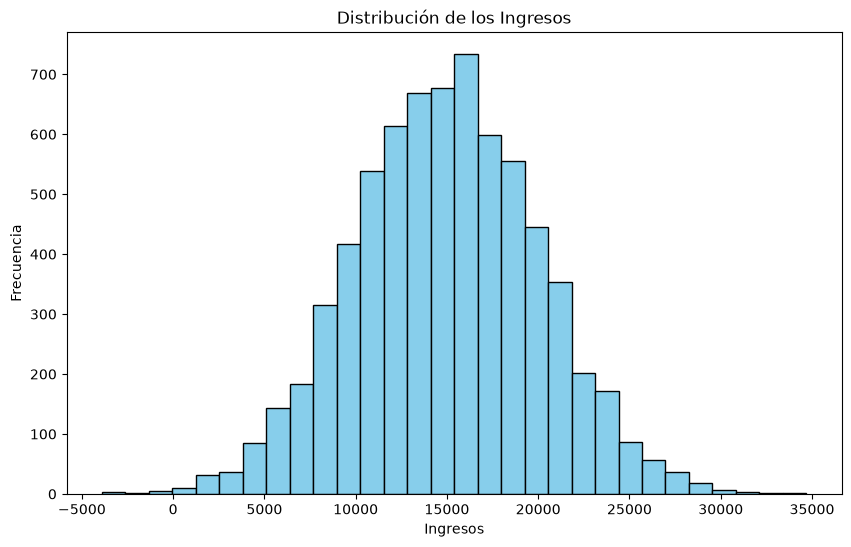

In [14]:
# Grafica de distribución de los ingresos
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.hist(df['ingresos'], bins=30, color='skyblue', edgecolor='black')
plt.title('Distribución de los Ingresos')
plt.xlabel('Ingresos')
plt.ylabel('Frecuencia')
plt.show()


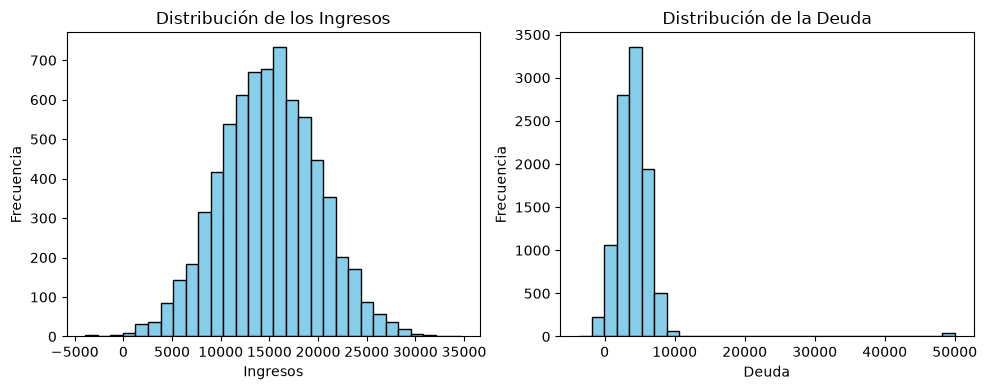

In [15]:
# Grafica de distribución de los ingresos (subplot-1) y la deuda (subplot-2) 
plt.figure(figsize=(10, 4))
# Subplot 1: Distribución de los ingresos
plt.subplot(1, 2, 1)
plt.hist(df['ingresos'], bins=30, color='skyblue', edgecolor='black')
plt.title('Distribución de los Ingresos')
plt.xlabel('Ingresos')
plt.ylabel('Frecuencia')

# Subplot 2: Distribución de la deuda
plt.subplot(1, 2, 2)
plt.hist(df['deuda'], bins=30, color='skyblue', edgecolor='black')
plt.title('Distribución de la Deuda')
plt.xlabel('Deuda')
plt.ylabel('Frecuencia')

plt.tight_layout()
plt.show()

In [16]:
# Diagnostico de los datos atípicos (outliers) mediante el método de Rango Intercuartílico (IQR)

# 1. Con respecto a los Ingresos
Q1_ingresos = df['ingresos'].quantile(0.25)
Q3_ingresos = df['ingresos'].quantile(0.75)
IQR_ingresos = Q3_ingresos - Q1_ingresos

LI_ingresos = Q1_ingresos - 1.5 * IQR_ingresos
LS_ingresos = Q3_ingresos + 1.5 * IQR_ingresos

outliers_ingresos = ((df['ingresos'] < LI_ingresos) | (df['ingresos']>LS_ingresos)).sum()
print(f"[Ingresos] Q1={Q1_ingresos:.2f}, Q3={Q3_ingresos:.2f}, IQR={IQR_ingresos:.2f}")
print(f"[Ingresos] Limite inferior(LI)={LI_ingresos:.2f}, Limite superior (LS)={LS_ingresos:.2f} ")
print(f"[Ingresos] Datos atípicos= {outliers_ingresos}")


[Ingresos] Q1=11479.54, Q3=18393.65, IQR=6914.10
[Ingresos] Limite inferior(LI)=1108.39, Limite superior (LS)=28764.80 
[Ingresos] Datos atípicos= 41


In [17]:
# 2. Con respecto a la Deuda
Q1_deuda = df['deuda'].quantile(0.25)
Q3_deuda = df['deuda'].quantile(0.75)
IQR_deuda = Q3_deuda - Q1_deuda

LI_deuda = Q1_deuda - 1.5 * IQR_deuda
LS_deuda = Q3_deuda + 1.5 * IQR_deuda

outliers_deuda = ((df['deuda'] < LI_deuda) | (df['deuda']>LS_deuda)).sum()
print(f"[deuda] Q1={Q1_deuda:.2f}, Q3={Q3_deuda:.2f}, IQR={IQR_deuda:.2f}")
print(f"[deuda] Limite inferior(LI)={LI_deuda:.2f}, Limite superior (LS)={LS_deuda:.2f} ")
print(f"[deuda] Datos atípicos= {outliers_deuda}")

[deuda] Q1=2622.23, Q3=5333.20, IQR=2710.97
[deuda] Limite inferior(LI)=-1444.23, Limite superior (LS)=9399.65 
[deuda] Datos atípicos= 102


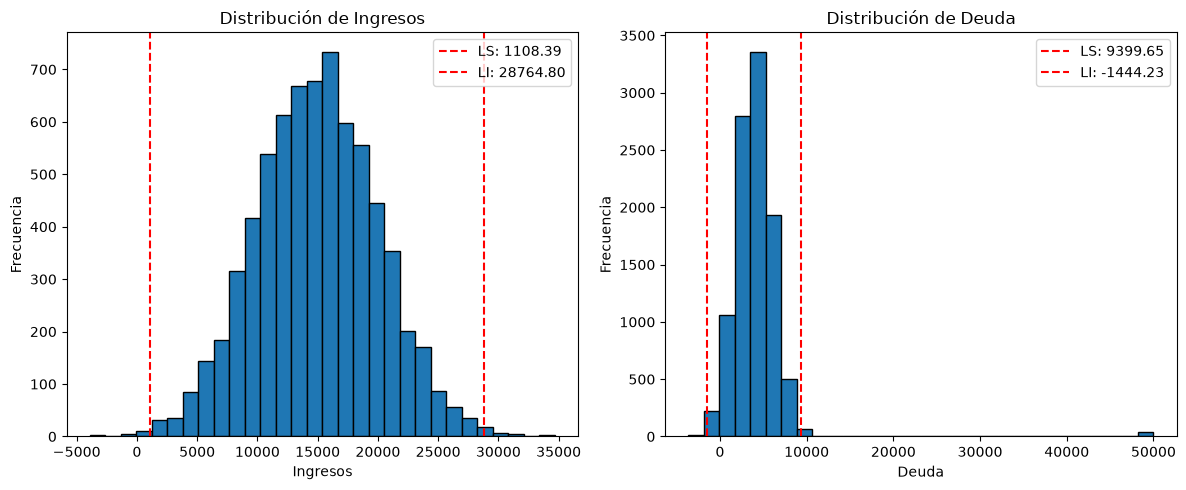

In [20]:
# Grafica de distribución de ingresos (subplot-1) y deuda (subplot-2) de tipo histograma con limites de outliers
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.hist(df['ingresos'], bins=30, edgecolor='black')
plt.xlabel('Ingresos')
plt.ylabel('Frecuencia')
plt.title('Distribución de Ingresos')
plt.axvline(LI_ingresos, color='r', linestyle='--', label=f'LS: {LI_ingresos:.2f}')
plt.axvline(LS_ingresos, color='r', linestyle='--', label=f'LI: {LS_ingresos:.2f}')
plt.legend()

plt.subplot(1, 2, 2)
plt.hist(df['deuda'], bins=30, edgecolor='black')
plt.xlabel('Deuda')
plt.ylabel('Frecuencia')
plt.title('Distribución de Deuda')
plt.axvline(LS_deuda, color='r', linestyle='--', label=f'LS: {LS_deuda:.2f}')
plt.axvline(LI_deuda, color='r', linestyle='--', label=f'LI: {LI_deuda:.2f}')
plt.legend()

plt.tight_layout()
plt.show()

### ---------------- Valores atípicos ------------------

In [ ]:
# Evaluación del coeficiente de asimetría (skewness) de la variable 'ingresos' y 'deuda'
skewness_ingresos_unique_na = df_sin_duplicados['ingresos'].skew()
skewness_deuda_unique_na = df_sin_duplicados['deuda'].skew()
print(f"Coeficiente de asimetría (skewness) de la variable 'ingresos': {skewness_ingresos_unique_na}")
print(f"Coeficiente de asimetría (skewness) de la variable 'deuda': {skewness_deuda_unique_na}")

Coeficiente de asimetría (skewness) de la variable 'ingresos': 0.07916144008970023
Coeficiente de asimetría (skewness) de la variable 'deuda': 8.859141717811807


In [76]:
# Diagnostico de los datos atípicos (outliers) mediante el método de Rango Intercuartílico (IQR)

# 1. Con respecto a los Ingresos
Q1_ingresos = df_sin_duplicados['ingresos'].quantile(0.25)
Q3_ingresos = df_sin_duplicados['ingresos'].quantile(0.75)
IQR_ingresos = Q3_ingresos - Q1_ingresos

LI_ingresos = Q1_ingresos - 1.75 * IQR_ingresos
LS_ingresos = Q3_ingresos + 1.75 * IQR_ingresos

outliers_ingresos = ((df_sin_duplicados['ingresos'] < LI_ingresos) | (df_sin_duplicados['ingresos']>LS_ingresos)).sum()
print(f"[Ingresos] Q1={Q1_ingresos:.2f}, Q3={Q3_ingresos:.2f}, IQR={IQR_ingresos:.2f}")
print(f"[Ingresos] Limite inferior(LI)={LI_ingresos:.2f}, Limite superior (LS)={LS_ingresos:.2f} ")
print(f"[Ingresos] Datos atípicos= {outliers_ingresos}")


[Ingresos] Q1=13091.16, Q3=16670.21, IQR=3579.05
[Ingresos] Limite inferior(LI)=6827.82, Limite superior (LS)=22933.55 
[Ingresos] Datos atípicos= 285


In [72]:
# 2. Con respecto a la Deuda
Q1_deuda = df_sin_duplicados['deuda'].quantile(0.25)
Q3_deuda = df_sin_duplicados['deuda'].quantile(0.75)
IQR_deuda = Q3_deuda - Q1_deuda

LI_deuda = Q1_deuda - 1.5 * IQR_deuda
LS_deuda = Q3_deuda + 1.5 * IQR_deuda

outliers_deuda = ((df_sin_duplicados['deuda'] < LI_deuda) | (df_sin_duplicados['deuda']>LS_deuda)).sum()
print(f"[deuda] Q1={Q1_deuda:.2f}, Q3={Q3_deuda:.2f}, IQR={IQR_deuda:.2f}")
print(f"[deuda] Limite inferior(LI)={LI_deuda:.2f}, Limite superior (LS)={LS_deuda:.2f} ")
print(f"[deuda] Datos atípicos= {outliers_deuda}")

[deuda] Q1=2708.78, Q3=5391.34, IQR=2682.55
[deuda] Limite inferior(LI)=-1315.04, Limite superior (LS)=9415.17 
[deuda] Datos atípicos= 37


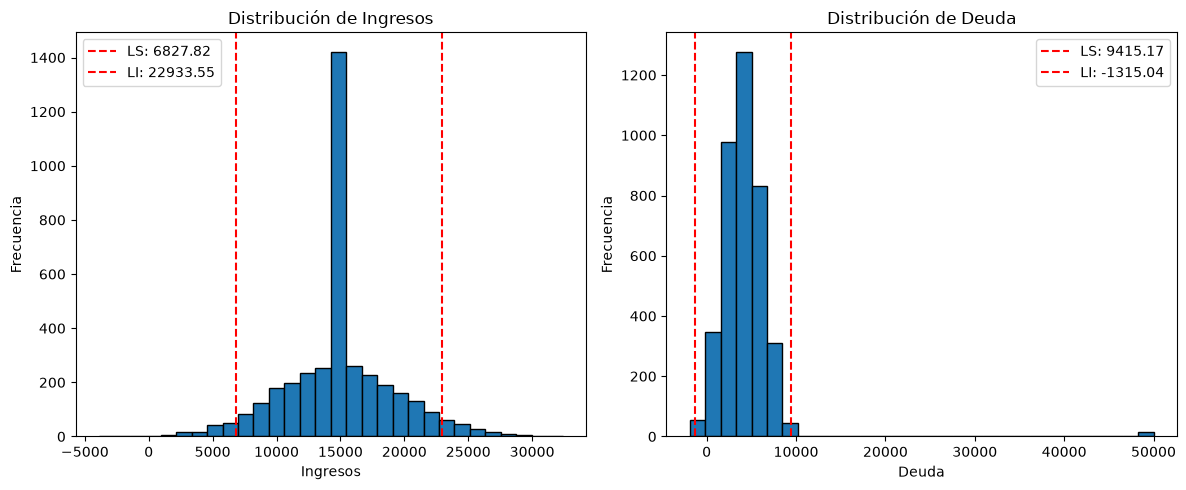

In [77]:
# Grafica de distribución de ingresos (subplot-1) y deuda (subplot-2) de tipo histograma con limites de outliers
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.hist(df_sin_duplicados['ingresos'], bins=30, edgecolor='black')
plt.xlabel('Ingresos')
plt.ylabel('Frecuencia')
plt.title('Distribución de Ingresos')
plt.axvline(LI_ingresos, color='r', linestyle='--', label=f'LS: {LI_ingresos:.2f}')
plt.axvline(LS_ingresos, color='r', linestyle='--', label=f'LI: {LS_ingresos:.2f}')
plt.legend()

plt.subplot(1, 2, 2)
plt.hist(df_sin_duplicados['deuda'], bins=30, edgecolor='black')
plt.xlabel('Deuda')
plt.ylabel('Frecuencia')
plt.title('Distribución de Deuda')
plt.axvline(LS_deuda, color='r', linestyle='--', label=f'LS: {LS_deuda:.2f}')
plt.axvline(LI_deuda, color='r', linestyle='--', label=f'LI: {LI_deuda:.2f}')
plt.legend()

plt.tight_layout()
plt.show()

In [79]:
# Eliminando los valores atípicos de la columna deudas
df_sin_duplicados = df_sin_duplicados[
    df_sin_duplicados["deuda"].between(LI_deuda, LS_deuda)
].copy()

In [82]:
# Eliminando los valores atípicos de la columna ingresos
df_sin_duplicados = df_sin_duplicados[
    df_sin_duplicados["ingresos"].between(LI_ingresos, LS_ingresos)
].copy()

In [83]:
df_sin_duplicados.info()

<class 'pandas.DataFrame'>
Index: 3538 entries, 0 to 4280
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   customer_id          3538 non-null   int64         
 1   edad                 3538 non-null   int64         
 2   ingresos             3538 non-null   float64       
 3   ciudad               3538 non-null   string        
 4   fecha_ultima_compra  3538 non-null   datetime64[us]
 5   num_compras          3538 non-null   int64         
 6   deuda                3538 non-null   float64       
 7   churn                3538 non-null   float64       
dtypes: datetime64[us](1), float64(3), int64(3), string(1)
memory usage: 248.8 KB


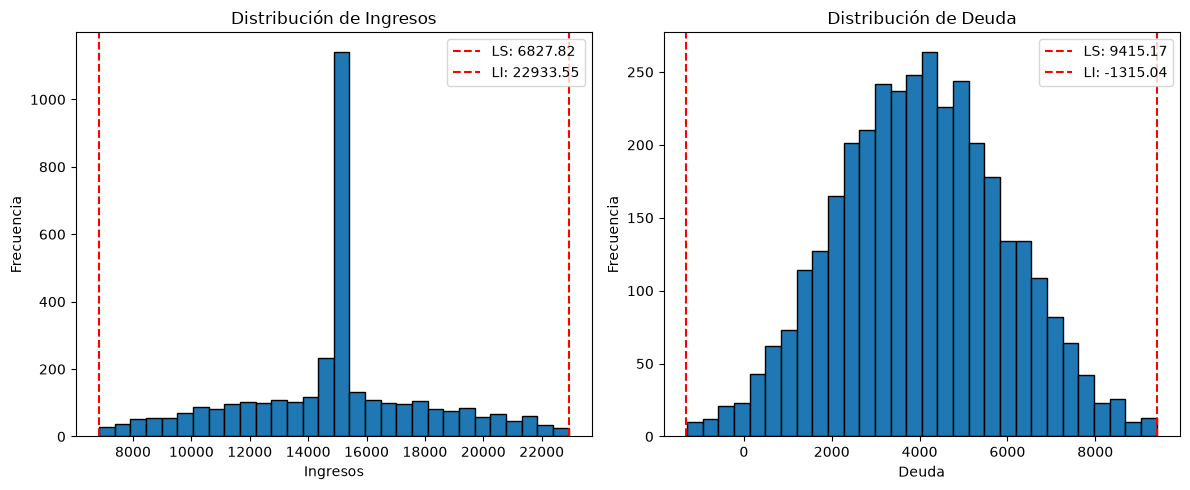

In [84]:
# Grafica de distribución de ingresos (subplot-1) y deuda (subplot-2) de tipo histograma con limites de outliers
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.hist(df_sin_duplicados['ingresos'], bins=30, edgecolor='black')
plt.xlabel('Ingresos')
plt.ylabel('Frecuencia')
plt.title('Distribución de Ingresos')
plt.axvline(LI_ingresos, color='r', linestyle='--', label=f'LS: {LI_ingresos:.2f}')
plt.axvline(LS_ingresos, color='r', linestyle='--', label=f'LI: {LS_ingresos:.2f}')
plt.legend()

plt.subplot(1, 2, 2)
plt.hist(df_sin_duplicados['deuda'], bins=30, edgecolor='black')
plt.xlabel('Deuda')
plt.ylabel('Frecuencia')
plt.title('Distribución de Deuda')
plt.axvline(LS_deuda, color='r', linestyle='--', label=f'LS: {LS_deuda:.2f}')
plt.axvline(LI_deuda, color='r', linestyle='--', label=f'LI: {LI_deuda:.2f}')
plt.legend()

plt.tight_layout()
plt.show()

In [97]:
# Diagnostico de los datos atípicos (outliers) mediante el método de Rango Intercuartílico (IQR)

# 1. Con respecto a la
Q1_edad = df_sin_duplicados['edad'].quantile(0.25)
Q3_edad = df_sin_duplicados['edad'].quantile(0.75)
IQR_edad = Q3_edad - Q1_edad

LI_edad = Q1_edad - 1.9 * IQR_edad
LS_edad = Q3_edad + 1.9 * IQR_edad

outliers_edad = ((df_sin_duplicados['edad'] < LI_edad) | (df_sin_duplicados['edad']>LS_edad)).sum()
print(f"[Edad] Q1={Q1_edad:.2f}, Q3={Q3_edad:.2f}, IQR={IQR_edad:.2f}")
print(f"[Edad] Limite inferior(LI)={LI_edad:.2f}, Limite superior (LS)={LS_edad:.2f} ")
print(f"[Edad] Datos atípicos= {outliers_edad}")

[Edad] Q1=32.00, Q3=48.00, IQR=16.00
[Edad] Limite inferior(LI)=1.60, Limite superior (LS)=78.40 
[Edad] Datos atípicos= 54


In [94]:
skewness_edad = df_sin_duplicados['edad'].skew()
print(f"Coeficiente de asimetría (skewness) de la variable 'edad': {skewness_edad}")

Coeficiente de asimetría (skewness) de la variable 'edad': 15.031528040566712


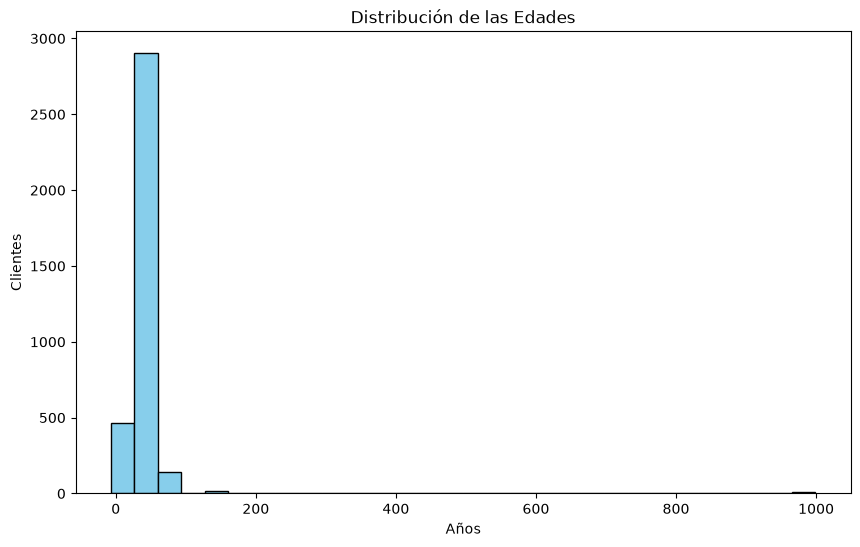

In [95]:
# Grafica de distribución de las Edades
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.hist(df_sin_duplicados['edad'], bins=30, color='skyblue', edgecolor='black')
plt.title('Distribución de las Edades')
plt.xlabel('Años')
plt.ylabel('Clientes')
plt.show()

C:\Users\pdani\AppData\Local\Temp\ipykernel_30904\50340313.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


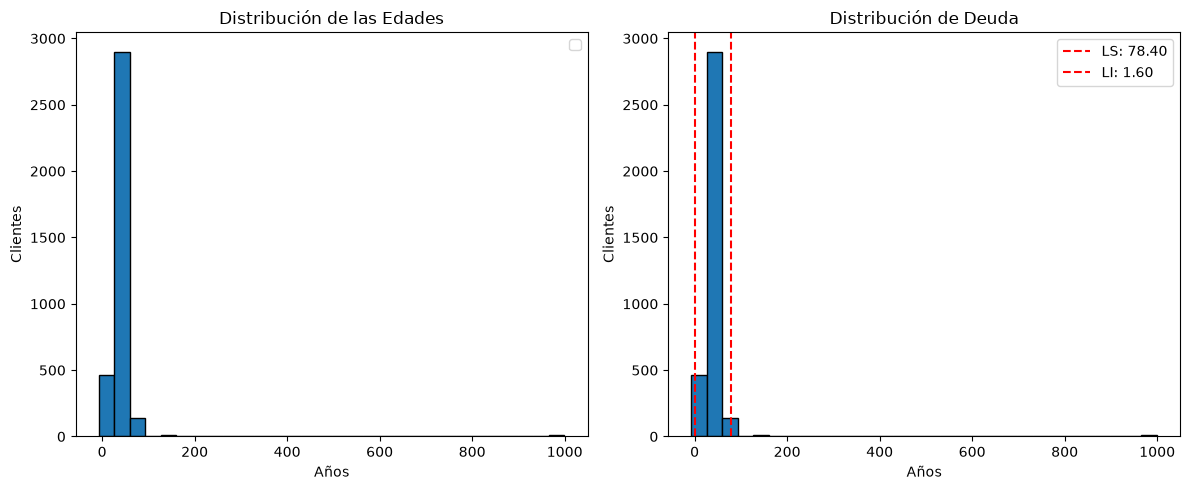

In [98]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.hist(df_sin_duplicados['edad'], bins=30, edgecolor='black')
plt.xlabel('Años')
plt.ylabel('Clientes')
plt.title('Distribución de las Edades')
plt.legend()

plt.subplot(1, 2, 2)
plt.hist(df_sin_duplicados['edad'], bins=30, edgecolor='black')
plt.xlabel('Años')
plt.ylabel('Clientes')
plt.title('Distribución de Deuda')
plt.axvline(LS_edad, color='r', linestyle='--', label=f'LS: {LS_edad:.2f}')
plt.axvline(LI_edad, color='r', linestyle='--', label=f'LI: {LI_edad:.2f}')
plt.legend()

plt.tight_layout()
plt.show()

In [99]:
# Eliminando los valores atípicos de la columna de edades
df_sin_duplicados = df_sin_duplicados[
    df_sin_duplicados["edad"].between(LI_edad, LS_edad)
].copy()

C:\Users\pdani\AppData\Local\Temp\ipykernel_30904\50340313.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


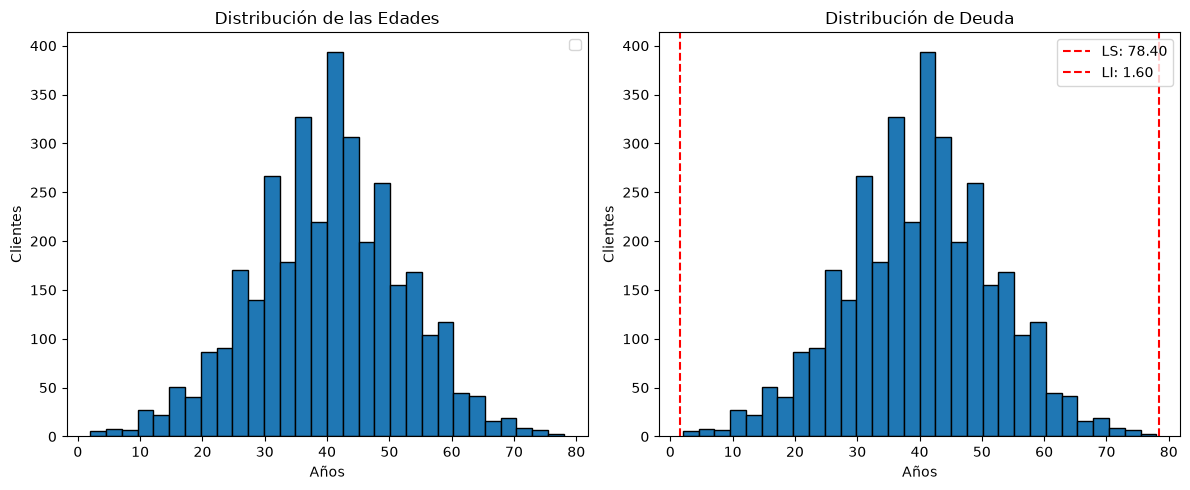

In [ ]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.hist(df_sin_duplicados['edad'], bins=30, edgecolor='black')
plt.xlabel('Años')
plt.ylabel('Clientes')
plt.title('Distribución de las Edades')
plt.legend()

plt.subplot(1, 2, 2)
plt.hist(df_sin_duplicados['edad'], bins=30, edgecolor='black')
plt.xlabel('Años')
plt.ylabel('Clientes')
plt.title('Distribución de Edad')
plt.axvline(LS_edad, color='r', linestyle='--', label=f'LS: {LS_edad:.2f}')
plt.axvline(LI_edad, color='r', linestyle='--', label=f'LI: {LI_edad:.2f}')
plt.legend()

plt.tight_layout()
plt.show()

### --------- Escalamiento de valores --------------------

In [85]:
# Importación de libreria para escalamiento
from sklearn.preprocessing import MinMaxScaler, StandardScaler

In [101]:
df_sin_duplicados.describe()

,customer_id,edad,ingresos,fecha_ultima_compra,num_compras,deuda,churn
count,3484.000000,3484.000000,3484.000000,3484,3484.000000,3484.000000,3484.000000
mean,3503.678530,40.093284,14859.606282,2023-03-01 15:24:10.746268,5.402411,4037.442170,0.505741
min,1001.000000,2.000000,6839.120000,2021-01-01 00:00:00,0.000000,-1293.130000,0.000000
25%,2264.750000,32.000000,13379.025000,2022-08-01 00:00:00,3.000000,2699.497500,0.000000
50%,3501.500000,40.000000,14914.310000,2023-05-06 00:00:00,5.000000,4032.510000,1.000000
75%,4733.500000,48.000000,16233.532500,2023-11-26 00:00:00,6.000000,5353.080000,1.000000
max,5998.000000,78.000000,22920.220000,2024-04-14 00:00:00,80.000000,9394.900000,1.000000
std,1434.659174,12.017270,3172.755063,NaN,6.215016,1929.490275,0.500039
